In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
def parse_cv_metrics(root_dir):
    dfs = []

    for dirpath, _, filenames in os.walk(root_dir):

        if "cv_all_folds_metrics.tsv" not in filenames:
            continue

        filepath = os.path.join(dirpath, "cv_all_folds_metrics.tsv")

        # path relative to root
        rel = os.path.relpath(dirpath, root_dir)
        parts = rel.split(os.sep)

        # Adjust this according to your folder structure
        if len(parts) < 3:
            continue

        dataset = parts[0]
        k = parts[1]
        model_type = parts[2]

        df = pd.read_csv(filepath, sep="\t")

        # add metadata
        df["dataset"] = dataset
        df["k"] = k
        #df["model_type"] = model_type

        dfs.append(df)

    # merge everything
    all_metrics = pd.concat(dfs, ignore_index=True)

    return all_metrics

In [49]:
def backbone(model):
    if "GCN" in model:
        return "GCN"
    elif "GAT" in model:
        return "GAT"
    elif "GIN" in model:
        return "GIN"
    else:
        return "Other"
        
def boxplot_comparison(df, metric_name, dataset):
    plot_df = df[
        (df["metric"] == metric_name) &
        (df["k"] == '4')
    ]
    plot_df["backbone"] = plot_df["model"].apply(backbone)

    plt.figure(figsize=(12,6))

    fig, ax = plt.subplots(figsize=(10, 6))

    sns.boxplot(
        data=plot_df,
        x="model",
        y="score",
        hue="backbone",
        ax=ax
    )

    sns.move_legend(
        ax,
        "upper left",
        bbox_to_anchor=(1.05, 1),
        title="Metric"
    )

    plt.xticks(rotation=45, ha="right")
    plt.title(f"Performance comparison: {metric_name} | {dataset}")
    plt.tight_layout()
    plt.show()

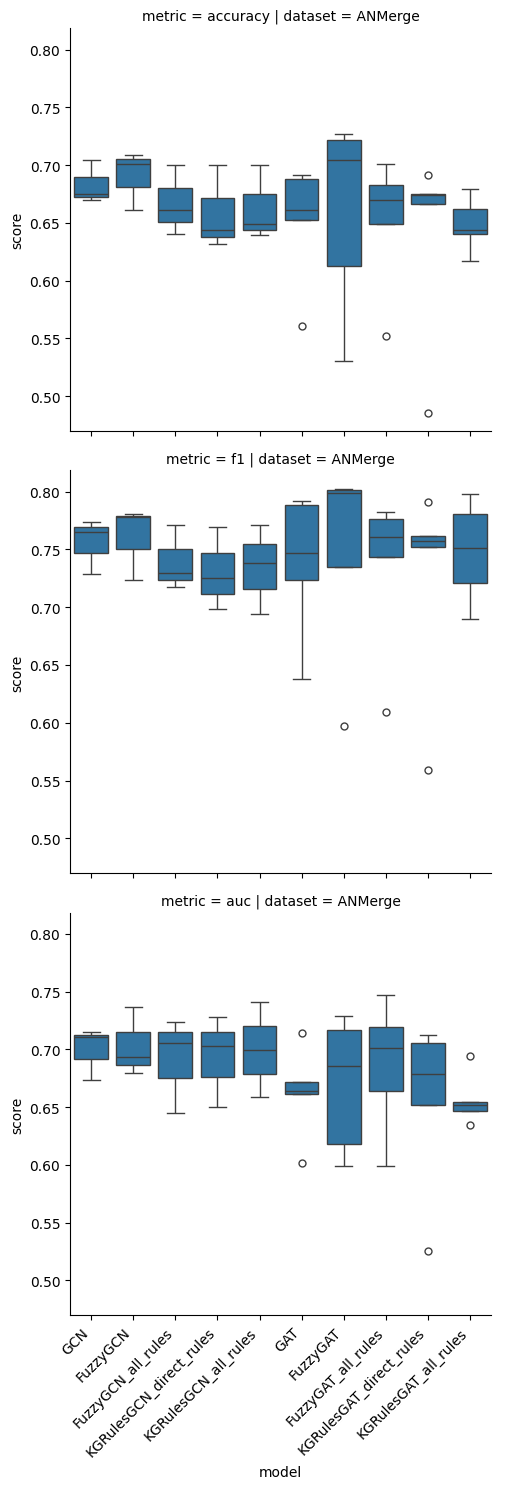

In [18]:
sns.catplot(
    data=df,
    x="model",
    y="score",
    col="dataset",
    row="metric",
    kind="box",
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

/tmp/ipykernel_506564/3652178690.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["backbone"] = plot_df["model"].apply(backbone)


<Figure size 1200x600 with 0 Axes>

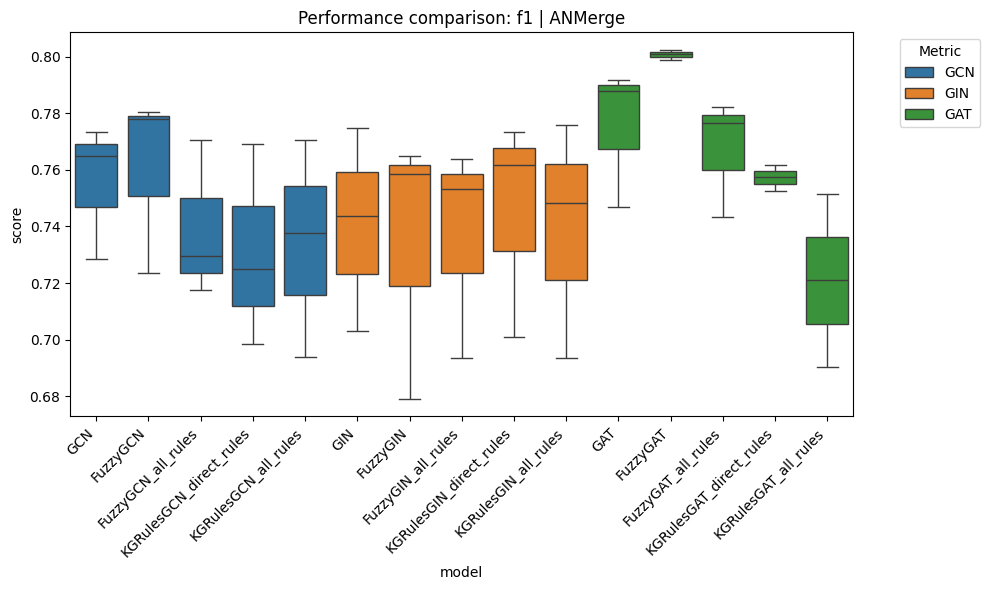

/tmp/ipykernel_506564/3652178690.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["backbone"] = plot_df["model"].apply(backbone)


<Figure size 1200x600 with 0 Axes>

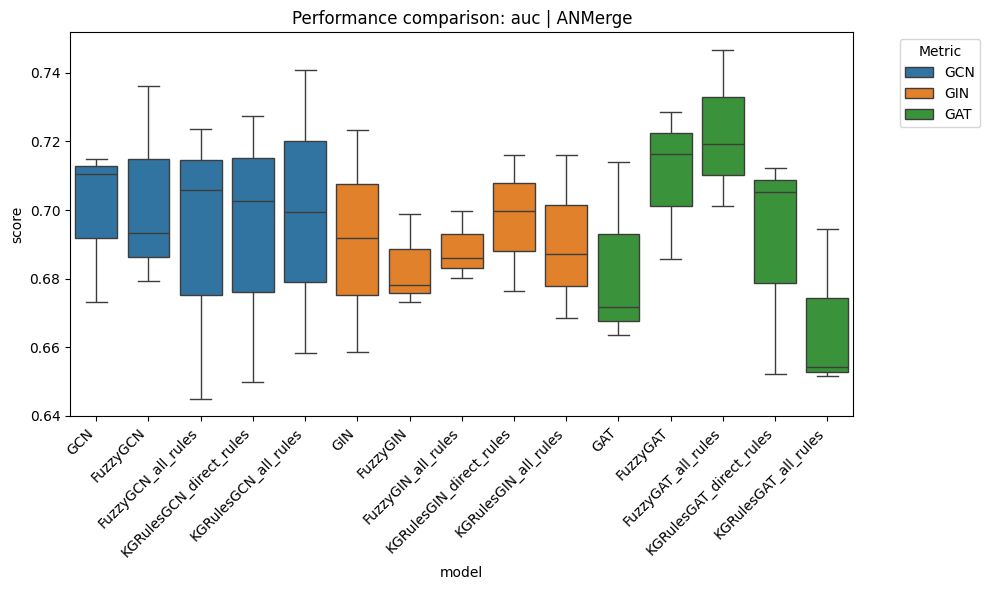

/tmp/ipykernel_506564/3652178690.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  plot_df["backbone"] = plot_df["model"].apply(backbone)


<Figure size 1200x600 with 0 Axes>

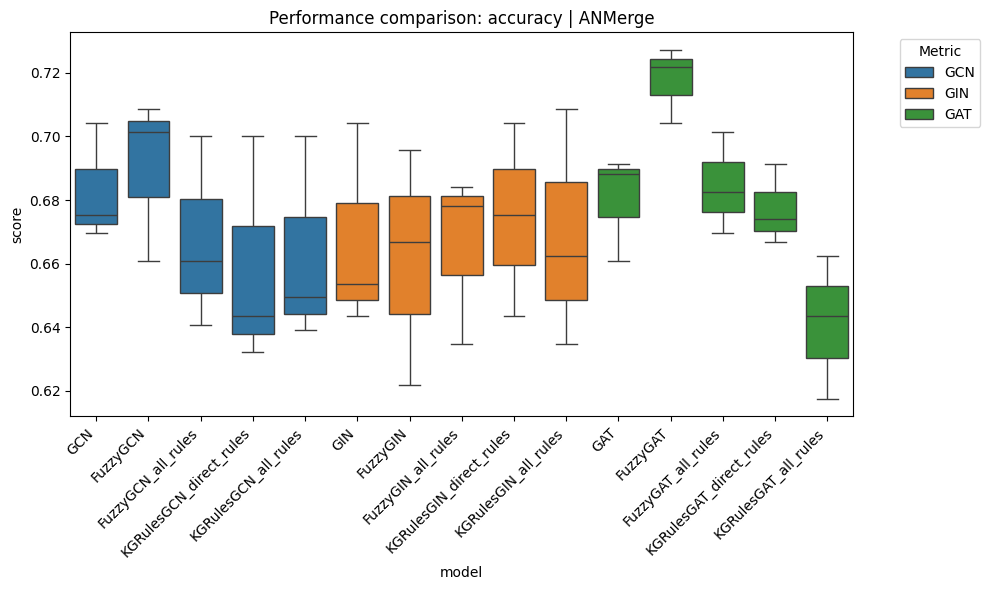

In [47]:
root_dir = "../nesy_gnn/results/AD_KG"
df_metrics = parse_cv_metrics(root_dir)
df = df_metrics.melt(
    id_vars=[
        "dataset",
        "k",
        "model",
        "fold"
    ],
    value_vars=["accuracy", "f1", "auc"],
    var_name="metric",
    value_name="score",
)
metric_name = 'f1'
dataset = 'ANMerge'
boxplot_comparison(df, 'f1', dataset)
boxplot_comparison(df, 'auc', dataset)
boxplot_comparison(df, 'accuracy', dataset)